# Exploratory Data Analysis: AI/GenAI Job Market

**Goal:** Quick overview of roles, salaries, skills, and work types in AI-related postings.

**Data:** Processed job postings (train + test).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import ast
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 12

PROJECT_DIR = Path('..').resolve()
TRAIN_PATH = PROJECT_DIR / 'data' / 'processed' / 'train.csv'
TEST_PATH = PROJECT_DIR / 'data' / 'processed' / 'test.csv'

## 1. Data Loading

In [4]:
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

df = pd.concat([df_train, df_test], ignore_index=True)

print("Data loaded:")
print(f"   Train: {len(df_train):,} samples")
print(f"   Test: {len(df_test):,} samples")
print(f"   Total: {len(df):,} samples")
print(f"   Columns: {df.shape[1]}")
print(f"\nAvailable columns: {list(df.columns)}")

Data loaded:
   Train: 2,780 samples
   Test: 696 samples
   Total: 3,476 samples
   Columns: 7

Available columns: ['job_id', 'title', 'description', 'max_salary', 'pay_period', 'formatted_work_type', 'skills']


In [5]:
df.head()

,job_id,title,description,max_salary,pay_period,formatted_work_type,skills
0,3904718968,"Manager, Analytics & Insights",\n\nPhreesia is looking for an Analytics & Ins...,NaN,NaN,Full-time,"['Research', 'Analyst', 'Information Technology']"
1,3900941781,VP of Marketing-AI,We are assisting a growing Gen AI startup with...,250000.0,YEARLY,Full-time,['Marketing']
2,3905257175,Patent Attorney,Title: Patent Attorney (Entrepreneurial-Minded...,700000.0,YEARLY,Full-time,"['Legal', 'Business Development', 'Consulting']"
3,3903828695,Implementation Specialist I,ADP is hiring an Implementation Specialist. \n...,27.4,HOURLY,Full-time,"['Customer Service', 'Accounting/Auditing']"
4,3890893537,Part-Time Remote Project Data Contributor (No ...,Position: Project Data ContributorProject Loca...,NaN,NaN,Contract,"['Information Technology', 'Art/Creative', 'Wr..."


## 2. Data Quality

In [5]:
missing_data = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

quality_df = pd.DataFrame({
    'Column': df.columns,
    'Missing Values': missing_data.values,
    'Percentage (%)': missing_pct.values
}).sort_values('Percentage (%)', ascending=False)

print("Data Quality Analysis:\n")
print(quality_df.to_string(index=False))
print(f"\nSamples with salary: {df['max_salary'].notna().sum():,} ({(df['max_salary'].notna().mean()*100):.1f}%)")

Data Quality Analysis:

             Column  Missing Values  Percentage (%)
         max_salary            2296           66.05
         pay_period            2224           63.98
             skills              62            1.78
        description               0            0.00
              title               0            0.00
             job_id               0            0.00
formatted_work_type               0            0.00

Samples with salary: 1,180 (33.9%)


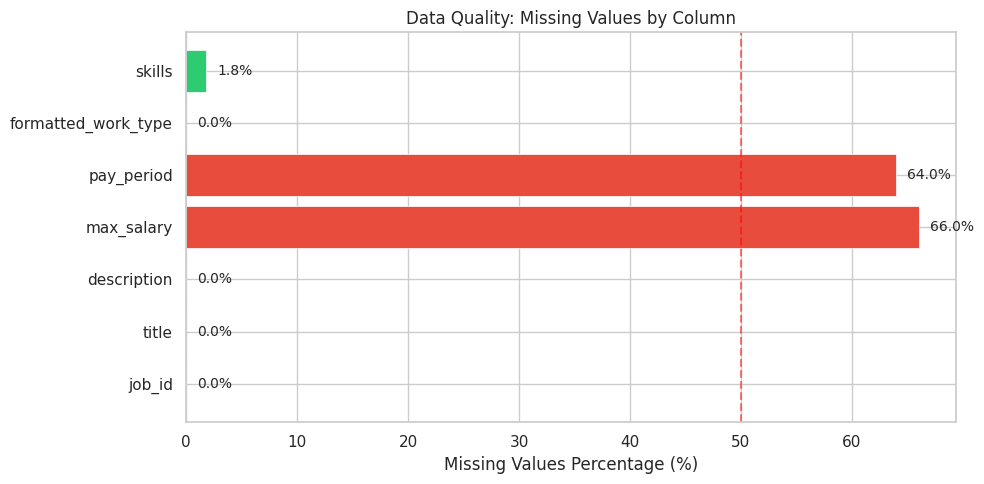

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#2ecc71' if pct < 10 else '#f39c12' if pct < 50 else '#e74c3c' for pct in missing_pct]
bars = ax.barh(df.columns, missing_pct.values, color=colors, edgecolor='white', linewidth=0.5)

ax.set_xlabel('Missing Values Percentage (%)')
ax.set_title('Data Quality: Missing Values by Column')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')

for bar, pct in zip(bars, missing_pct.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()

# 3.  Job Titles Analysis

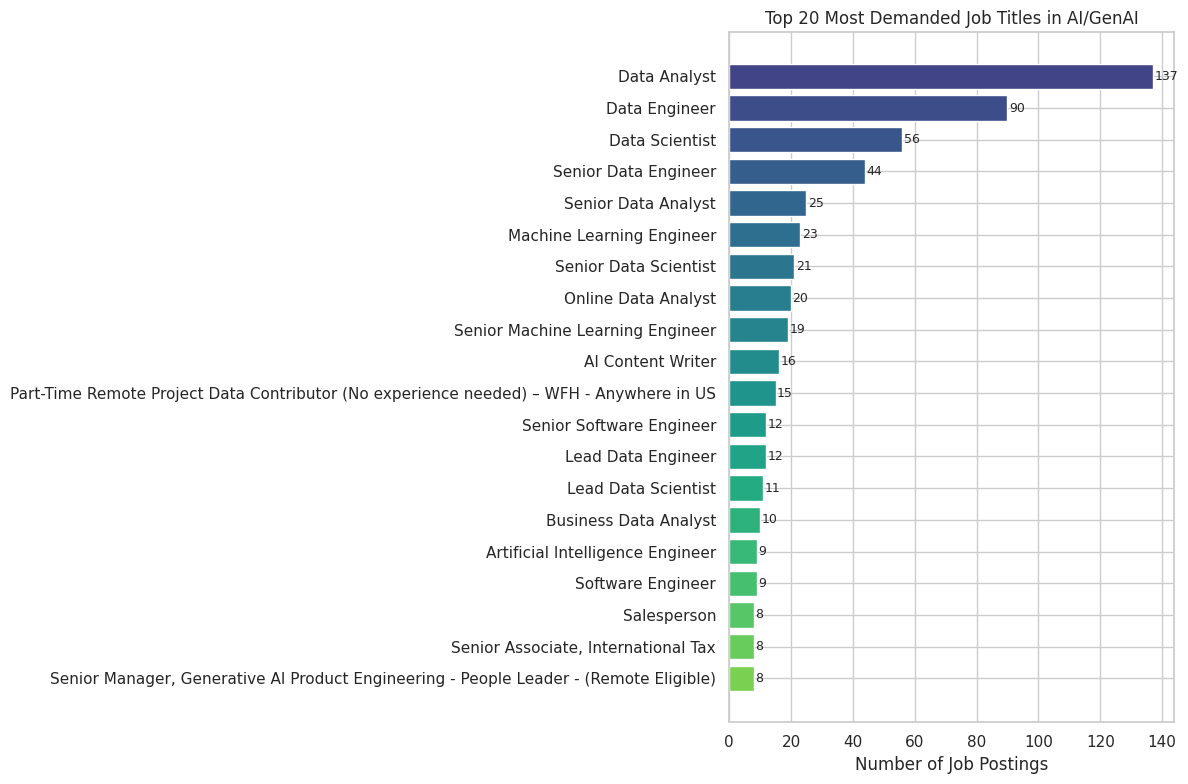


Role diversity: 2,419 unique titles


In [7]:
# Top 20 most common job titles
title_counts = df['title'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(title_counts)))

bars = ax.barh(title_counts.index[::-1], title_counts.values[::-1], color=colors[::-1])
ax.set_xlabel('Number of Job Postings')
ax.set_title('Top 20 Most Demanded Job Titles in AI/GenAI')

# Add value labels to bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{int(width)}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"\nRole diversity: {df['title'].nunique():,} unique titles")

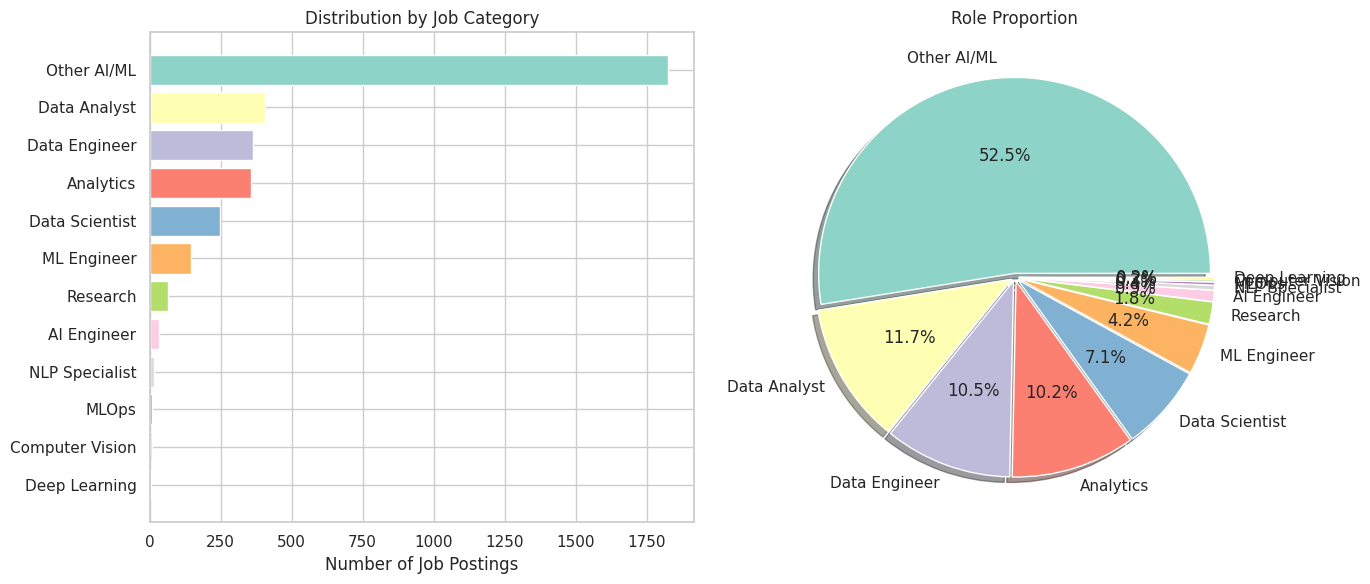

In [8]:
# Categorize job titles by keywords
def categorize_job(title):
    title_lower = str(title).lower()
    if 'data scientist' in title_lower:
        return 'Data Scientist'
    elif 'data engineer' in title_lower:
        return 'Data Engineer'
    elif 'data analyst' in title_lower:
        return 'Data Analyst'
    elif 'machine learning' in title_lower or 'ml engineer' in title_lower:
        return 'ML Engineer'
    elif 'ai engineer' in title_lower:
        return 'AI Engineer'
    elif 'nlp' in title_lower or 'natural language' in title_lower:
        return 'NLP Specialist'
    elif 'computer vision' in title_lower or 'cv engineer' in title_lower:
        return 'Computer Vision'
    elif 'mlops' in title_lower:
        return 'MLOps'
    elif 'research' in title_lower and ('scientist' in title_lower or 'engineer' in title_lower):
        return 'Research'
    elif 'analytics' in title_lower:
        return 'Analytics'
    elif 'deep learning' in title_lower:
        return 'Deep Learning'
    else:
        return 'Other AI/ML'

df['job_category'] = df['title'].apply(categorize_job)

category_counts = df['job_category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart
colors = plt.cm.Set3(np.linspace(0, 1, len(category_counts)))
axes[0].barh(category_counts.index[::-1], category_counts.values[::-1], color=colors[::-1])
axes[0].set_xlabel('Number of Job Postings')
axes[0].set_title('Distribution by Job Category')

# Pie chart
explode = [0.02] * len(category_counts)
axes[1].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%', 
            colors=colors, explode=explode, shadow=True)
axes[1].set_title('Role Proportion')

plt.tight_layout()
plt.show()

## 4.  Salary analysis

In [9]:
# Filter postings with valid salary (annual > $20k and < $500k)
df_salary = df[(df['max_salary'].notna()) & (df['max_salary'] > 20000) & (df['max_salary'] < 500000)].copy()

print(f"Postings with valid salary: {len(df_salary):,}")
print("\nMax Salary Statistics:")
print(df_salary['max_salary'].describe().apply(lambda x: f"${x:,.0f}" if x > 100 else f"{x:.2f}"))

Postings with valid salary: 969

Max Salary Statistics:
count        $969
mean     $189,838
std       $69,678
min       $40,000
25%      $139,620
50%      $180,000
75%      $234,500
max      $472,900
Name: max_salary, dtype: object


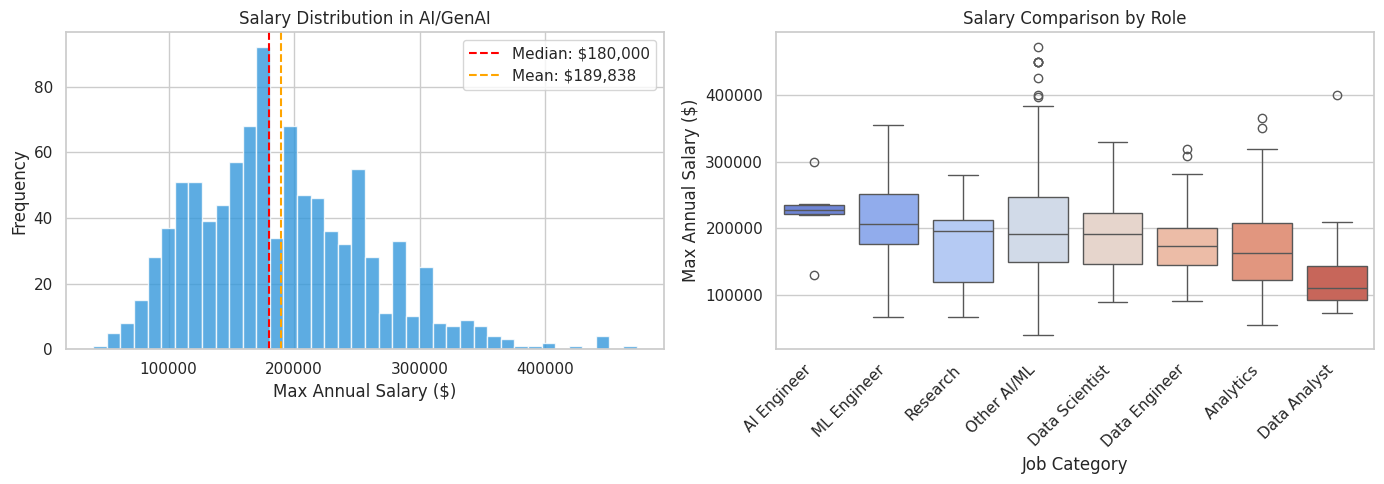

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Salary distribution histogram
axes[0].hist(df_salary['max_salary'], bins=40, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(df_salary['max_salary'].median(), color='red', linestyle='--', 
                label=f'Median: ${df_salary["max_salary"].median():,.0f}')
axes[0].axvline(df_salary['max_salary'].mean(), color='orange', linestyle='--', 
                label=f'Mean: ${df_salary["max_salary"].mean():,.0f}')
axes[0].set_xlabel('Max Annual Salary ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Salary Distribution in AI/GenAI')
axes[0].legend()

# Box plot by job category
top_categories = df_salary['job_category'].value_counts().head(8).index
df_salary_top = df_salary[df_salary['job_category'].isin(top_categories)]

# Order categories by median salary
category_order = df_salary_top.groupby('job_category')['max_salary'].median().sort_values(ascending=False).index
sns.boxplot(data=df_salary_top, x='job_category', y='max_salary', order=category_order, ax=axes[1], palette='coolwarm')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_xlabel('Job Category')
axes[1].set_ylabel('Max Annual Salary ($)')
axes[1].set_title('Salary Comparison by Role')

plt.tight_layout()
plt.show()

In [11]:
# Aggregate salary statistics by job category
salary_by_category = df_salary.groupby('job_category')['max_salary'].agg(['median', 'mean', 'min', 'max', 'count'])
salary_by_category = salary_by_category.sort_values('median', ascending=False)
salary_by_category.columns = ['Median', 'Mean', 'Minimum', 'Maximum', 'Postings']

# Format as currency
for col in ['Median', 'Mean', 'Minimum', 'Maximum']:
    salary_by_category[col] = salary_by_category[col].apply(lambda x: f"${x:,.0f}")

print("Salary Table by Job Category:\n")
salary_by_category

Salary Table by Job Category:



,Median,Mean,Minimum,Maximum,Postings
job_category,,,,,
Computer Vision,"$248,000","$248,000","$246,000","$250,000",2
NLP Specialist,"$230,350","$230,350","$200,700","$260,000",2
AI Engineer,"$227,500","$223,645","$130,000","$300,000",6
MLOps,"$225,000","$220,000","$180,000","$250,000",4
ML Engineer,"$207,000","$221,608","$66,295","$355,000",46
Deep Learning,"$202,730","$207,672","$202,730","$222,500",4
Research,"$195,200","$175,979","$67,000","$280,000",21
Other AI/ML,"$192,000","$199,387","$40,000","$472,900",559
Data Scientist,"$190,758","$190,389","$88,926","$329,333",74


## 5.  Skills analysis

In [12]:
# Parse skills from string representation to list
def parse_skills(skill_str):
    if pd.isna(skill_str):
        return []
    try:
        if isinstance(skill_str, str):
            return ast.literal_eval(skill_str)
        return []
    except Exception:
        return []

df['skills_list'] = df['skills'].apply(parse_skills)

# Flatten skills lists and count occurrences
all_skills = [skill for sublist in df['skills_list'] for skill in sublist]
skill_counts = Counter(all_skills)

print(f"Total skill mentions: {len(all_skills):,}")
print(f"Unique skills: {len(skill_counts):,}")

Total skill mentions: 6,087
Unique skills: 35


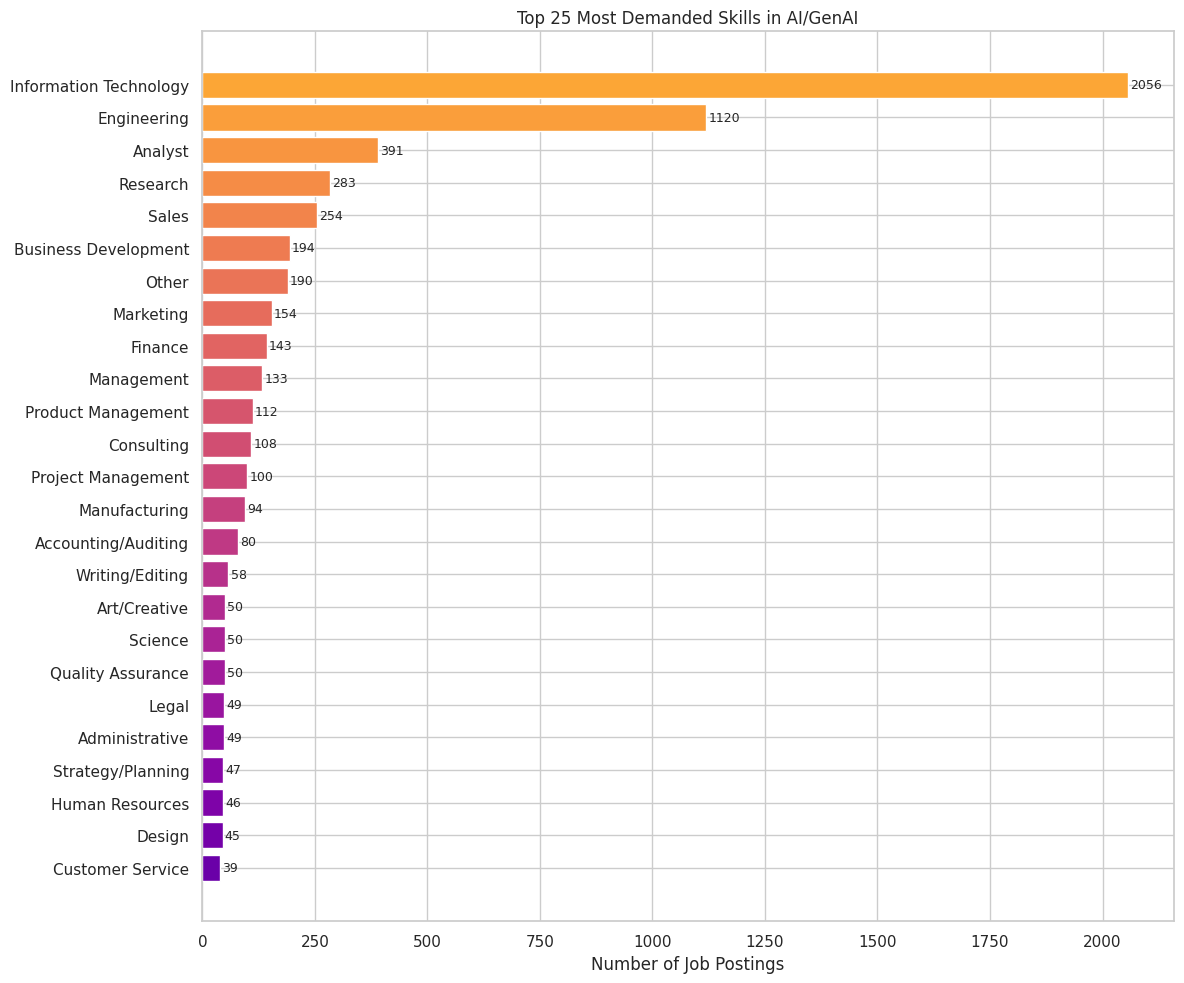

In [13]:
# Top 25 most demanded skills
top_skills = skill_counts.most_common(25)

fig, ax = plt.subplots(figsize=(12, 10))
skills_names = [s[0] for s in top_skills][::-1]
skills_counts = [s[1] for s in top_skills][::-1]

colors = plt.cm.plasma(np.linspace(0.2, 0.8, len(skills_names)))
bars = ax.barh(skills_names, skills_counts, color=colors)

ax.set_xlabel('Number of Job Postings')
ax.set_title('Top 25 Most Demanded Skills in AI/GenAI')

# Add value labels to bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2, 
            f'{int(width)}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6.  Work types

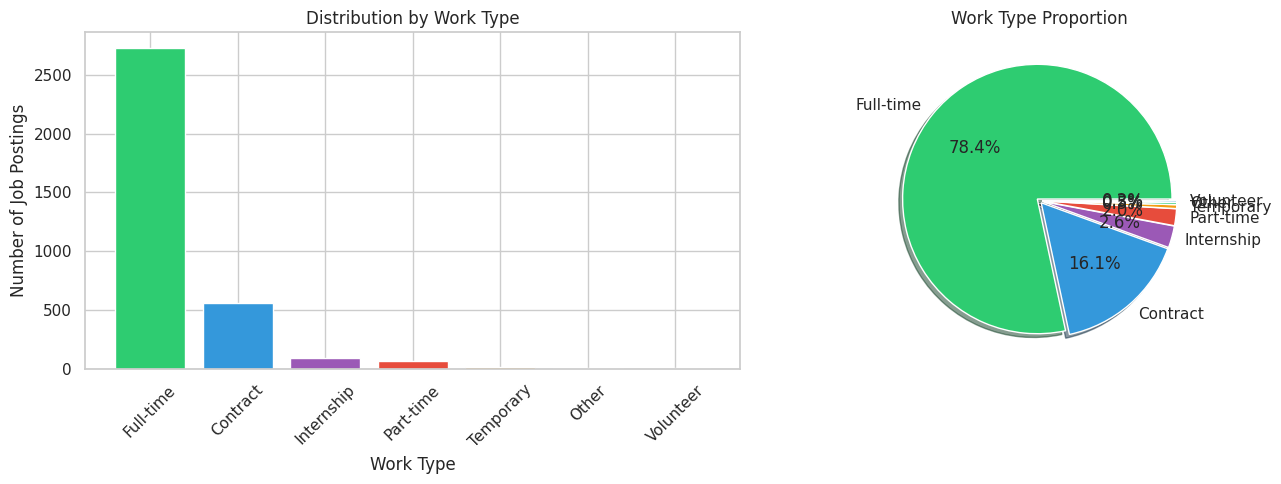

In [14]:
# Work type distribution analysis
work_type_counts = df['formatted_work_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e74c3c', '#f39c12']
axes[0].bar(work_type_counts.index, work_type_counts.values, color=colors[:len(work_type_counts)])
axes[0].set_xlabel('Work Type')
axes[0].set_ylabel('Number of Job Postings')
axes[0].set_title('Distribution by Work Type')
axes[0].tick_params(axis='x', rotation=45)

# Pie chart
axes[1].pie(work_type_counts.values, labels=work_type_counts.index, autopct='%1.1f%%',
            colors=colors[:len(work_type_counts)], explode=[0.02]*len(work_type_counts), shadow=True)
axes[1].set_title('Work Type Proportion')

plt.tight_layout()
plt.show()

## 7.  Executive Summary

In [15]:
# Executive summary
print("="*60)
print("EXECUTIVE SUMMARY: Generative AI Job Market")
print("="*60)
print(f"""
DATA VOLUME
  • Total postings analyzed: {len(df):,}
  • Unique job titles: {df['title'].nunique():,}
  • Postings with salary: {df['max_salary'].notna().sum():,} ({(df['max_salary'].notna().mean()*100):.1f}%)

SALARY INSIGHTS
  • Median salary: ${df_salary['max_salary'].median():,.0f}
  • Average salary: ${df_salary['max_salary'].mean():,.0f}
  • Salary range: ${df_salary['max_salary'].min():,.0f} - ${df_salary['max_salary'].max():,.0f}

TOP 5 MOST DEMANDED ROLES
""")
for i, (role, count) in enumerate(category_counts.head(5).items(), 1):
    print(f"  {i}. {role}: {count:,} postings")

print("""
TOP 5 MOST DEMANDED SKILLS
""")
for i, (skill, count) in enumerate(skill_counts.most_common(5), 1):
    print(f"  {i}. {skill}: {count:,} mentions")

print("\n" + "="*60)

EXECUTIVE SUMMARY: Generative AI Job Market

DATA VOLUME
  • Total postings analyzed: 3,476
  • Unique job titles: 2,419
  • Postings with salary: 1,180 (33.9%)

SALARY INSIGHTS
  • Median salary: $180,000
  • Average salary: $189,838
  • Salary range: $40,000 - $472,900

TOP 5 MOST DEMANDED ROLES

  1. Other AI/ML: 1,826 postings
  2. Data Analyst: 405 postings
  3. Data Engineer: 365 postings
  4. Analytics: 356 postings
  5. Data Scientist: 247 postings

TOP 5 MOST DEMANDED SKILLS

  1. Information Technology: 2,056 mentions
  2. Engineering: 1,120 mentions
  3. Analyst: 391 mentions
  4. Research: 283 mentions
  5. Sales: 254 mentions



In [16]:
# Prepare final dataset
df_enriched = df.drop(columns=['skills_list'], errors='ignore')
print("\nAnalysis completed. Dataset ready for next phase.")
print(f"Final columns: {list(df.columns)}")


Analysis completed. Dataset ready for next phase.
Final columns: ['job_id', 'title', 'description', 'max_salary', 'pay_period', 'formatted_work_type', 'skills', 'job_category', 'skills_list']
